# Архитектура LLM I · от текста до работающего decoder
**МФТИ / girafe-ai · PyTorch, матрицы, проверяемые гипотезы**

Что отличает последовательность от набора токенов? Почему GPT не подсматривает ответ?
Что именно меняется, когда в модель добавляют RoPE, RMSNorm и SwiGLU?

В этом ноутбуке вы научитесь читать размеры тензоров, поймёте, зачем нужны маска и позиции,
и соберёте маленькую авторегрессионную языковую модель.
**Авторегрессия**: следующий токен предсказывается по уже известному префиксу.

Что понадобится: умножение матриц, производные, базовые `torch.Tensor`, `nn.Module`, `backward`.
Все новые архитектурные понятия определены ниже. Модель учебная, это не точная копия Llama/Mistral.

**Связь с курсом:** в RAG вы пользовались готовыми моделями, теперь разберём, как они устроены внутри.
Дальше в курсе: стоимость контекста и KV-cache, затем MoE и более сложные архитектуры.

| Раздел | Вопрос блока |
|---|---|
| 1. Текст, токены, embeddings | Как текст становится матрицей? |
| 2. Attention и порядок | Знает ли attention порядок без позиций? |
| 3. Позиционные представления | Где и как появляется расстояние? |
| 4. Encoder и decoder | Кто имеет право смотреть в будущее? |
| 5. Устройство блока | Зачем residual, нормализация, gating? |
| 6. Языковая модель и итоги | Как из блока получить обучение и генерацию? |

Код уже написан: запускайте ячейки и меняйте отдельные строки, набирать всё с нуля не нужно.
Перед каждой проверкой попробуйте сначала предсказать результат.

### Как запустить
1. Откройте ноутбук в Jupyter / VS Code / Colab и выберите Python-ядро.
2. Нужны `torch`, `numpy`, `matplotlib`. Если их нет: `%pip install torch numpy matplotlib`.
3. После установки перезапустите ядро и выполните **Restart Kernel → Run All**.
4. Интернет после установки не нужен: все данные создаются внутри ноутбука.

По умолчанию всё считается на CPU: маленькая модель, 180 шагов обучения. GPU и API-ключи не нужны.
Если поставить `RUN_TRAINING=False`, обучение пропустится, а генерация пойдёт от случайной модели (это будет подписано в выводе).

In [1]:
import math
import random
import time
from collections import Counter
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cpu")
RUN_TRAINING = True
TRAIN_STEPS = 180

plt.rcParams.update({"figure.figsize": (9, 3.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print("PyTorch:", torch.__version__, "| устройство:", DEVICE)


def heatmap(ax, matrix, title, xlabel="Ключ j", ylabel="Запрос i", **kwargs):
    """Одинаковые подписи для матриц attention и позиционных кодов."""
    if isinstance(matrix, torch.Tensor):
        matrix = matrix.detach().cpu().numpy()
    image = ax.imshow(matrix, aspect="auto", **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    return image

PyTorch: 2.5.1 | устройство: cpu


## 1 · Текст → токены → embeddings
**Зачем:** модель умеет только умножать матрицы, поэтому строку сначала нужно превратить в числа.

**Токен** — единица текста из фиксированного словаря. **ID** — целочисленный номер токена.
**Токенизатор** задаёт `encode: текст → ID` и `decode: ID → текст`.

| Способ | Идея | Цена |
|---|---|---|
| Символы | Один символ — один токен | Длинные последовательности; неизвестные символы требуют обработки |
| Слова | Одно слово — один токен | Большой словарь; проблема новых слов |
| BPE | Последовательно объединять частые соседние пары | Компромисс между длиной последовательности и словарём |
| WordPiece / Unigram | Другие способы построить подсловный словарь и сегментацию | Здесь только упоминаем, без реализации |

**BPE — Byte Pair Encoding.** Ниже учебный вариант над символами и внутри слов:
взвешиваем пары частотами слов, выбираем самую частую, заменяем непересекающиеся вхождения.
В реальных токенизаторах есть дополнительные правила; byte-level BPE стартует с байтов.

In [2]:
def merge_pair(tokens, pair):
    """Заменить непересекающиеся вхождения пары, сохранив порядок."""
    result, i = [], 0
    while i < len(tokens):
        if i + 1 < len(tokens) and (tokens[i], tokens[i + 1]) == pair:
            result.append(tokens[i] + tokens[i + 1])
            i += 2
        else:
            result.append(tokens[i])
            i += 1
    return tuple(result)


def fit_toy_bpe(word_counts, steps=5):
    words = {tuple(word): count for word, count in word_counts.items()}
    merges = []
    for _ in range(steps):
        pairs = Counter()
        for tokens, count in words.items():
            for pair in zip(tokens, tokens[1:]):
                pairs[pair] += count
        if not pairs:
            break
        best = max(pairs, key=lambda pair: (pairs[pair], pair))
        merges.append(best)
        updated = Counter()
        for tokens, count in words.items():
            updated[merge_pair(tokens, best)] += count
        words = dict(updated)
        print(f"{best} → {''.join(best)!r}; частота пары = {pairs[best]}")
    return merges


def encode_toy_bpe(word, merges):
    tokens = tuple(word)
    for pair in merges:
        tokens = merge_pair(tokens, pair)
    return tokens


bpe_merges = fit_toy_bpe({"low": 5, "lower": 2, "lowest": 2, "newer": 3})
for word in ["lower", "lowest", "newest"]:
    print(word, "→", encode_toy_bpe(word, bpe_merges))

('o', 'w') → 'ow'; частота пары = 9
('l', 'ow') → 'low'; частота пары = 9
('e', 'r') → 'er'; частота пары = 5
('w', 'er') → 'wer'; частота пары = 3
('n', 'e') → 'ne'; частота пары = 3
lower → ('low', 'er')
lowest → ('low', 'e', 's', 't')
newest → ('ne', 'w', 'e', 's', 't')


**Вопрос 1.** Что происходит с длиной последовательности и размером словаря, когда мы объединяем пару? Почему один токен — не обязательно одно слово?

### Embedding — обучаемая таблица, а не число со «смыслом»
Обозначения для всего ноутбука:

| Символ | Значение |
|---|---|
| $B$ | число последовательностей в batch (пакете) |
| $T$ | длина последовательности в токенах |
| $V$ | размер словаря |
| $d$ | ширина представления одного токена |
| $H$ | число голов attention; $d_h=d/H$ — ширина головы |
| $d_{ff}$ | внутренняя ширина feed-forward (MLP) |
| $N$ | число Transformer-блоков |

Таблица $E\in\mathbb R^{V\times d}$. Для ID $s_t$ берём строку $E_{s_t}$.
После lookup получаем $X\in\mathbb R^{B\times T\times d}$.
Индекс $t$ обозначает позицию, $X$ — входные векторы.
Числовая близость ID **не** задаёт близость embeddings.

Для модели дальше используем символы: это упрощает наблюдение за входом и выходом.
Номер символа не содержит его позиции.

In [3]:
class CharTokenizer:
    def __init__(self, alphabet):
        self.tokens = sorted(set(alphabet))
        self.to_id = {token: i for i, token in enumerate(self.tokens)}

    def encode(self, text):
        unknown = set(text) - self.to_id.keys()
        # <SOS>, <EOS>, <PAD>, <UKN>
        if unknown:
            raise ValueError(f"Неизвестные символы: {unknown}")
        return [self.to_id[token] for token in text]

    def decode(self, ids):
        return "".join(self.tokens[int(i)] for i in ids)

    def __len__(self):
        return len(self.tokens)


example_text = "кот спит"
example_tokenizer = CharTokenizer(example_text)
ids = torch.tensor([example_tokenizer.encode(example_text)])
embedding = nn.Embedding(len(example_tokenizer), 8)
x_example = embedding(ids)
print("Текст:", example_text)
print("ID:", ids.tolist(), "| shape:", tuple(ids.shape))
print("Embedding shape:", tuple(x_example.shape))
one_hot = F.one_hot(ids, num_classes=len(example_tokenizer)).float()
torch.testing.assert_close(x_example, one_hot @ embedding.weight)
print("Lookup совпадает с one-hot @ E, но не создаёт большую one-hot матрицу.")

Текст: кот спит
ID: [[2, 3, 6, 0, 5, 4, 1, 6]] | shape: (1, 8)
Embedding shape: (1, 8, 8)
Lookup совпадает с one-hot @ E, но не создаёт большую one-hot матрицу.


**Вопрос 2.** Что изменится, если переставить номера в словаре и так же переставить строки $E$?
Чем embedding lookup отличается от pooling, который вы видели в E5?

## 2 · Self-attention и порядок
**Зачем:** embedding символа одинаков в любом контексте. Чтобы учесть контекст, нужно собрать информацию от других позиций.

Начнём с одной головы и одной последовательности:

$$Q=XW_Q,\quad K=XW_K,\quad V_{\!a}=XW_V,$$
$$S=QK^\top/\sqrt{d_h}+M,\qquad A=\operatorname{softmax}_{\text{по строке}}(S),\qquad Y=AV_{\!a}.$$

- $W_Q,W_K,W_V$ — обучаемые матрицы проекций, размер $d\times d_h$.
- $Q$ — запросы («что ищу»), $K$ — ключи («с чем сравнить»), $V_a$ — значения («что передать»).
  Здесь $V_a$ — матрица значений, **не** размер словаря $V$.
- $S_{ij}$ — score между запросом позиции $i$ и ключом позиции $j$.
- $M$ — добавочная маска: $0$ для разрешённых связей, $-\infty$ для запрещённых.
- $A_{ij}$ — вес передачи значения $j$ в выход $i$; каждая строка $A$ суммируется в 1.
- $Y$ — выход; $\top$ — транспонирование, `@` — матричное умножение.

Softmax: $\operatorname{softmax}(s)_j=e^{s_j}/\sum_k e^{s_k}$; $s$ — одна строка scores.
При независимых координатах $q,k$ с нулевым средним и единичной дисперсией
$\operatorname{Var}(q^\top k)=d_h$. Деление на $\sqrt{d_h}$ контролирует масштаб scores;
это мотивирующее приближение, а не утверждение об обученных векторах.

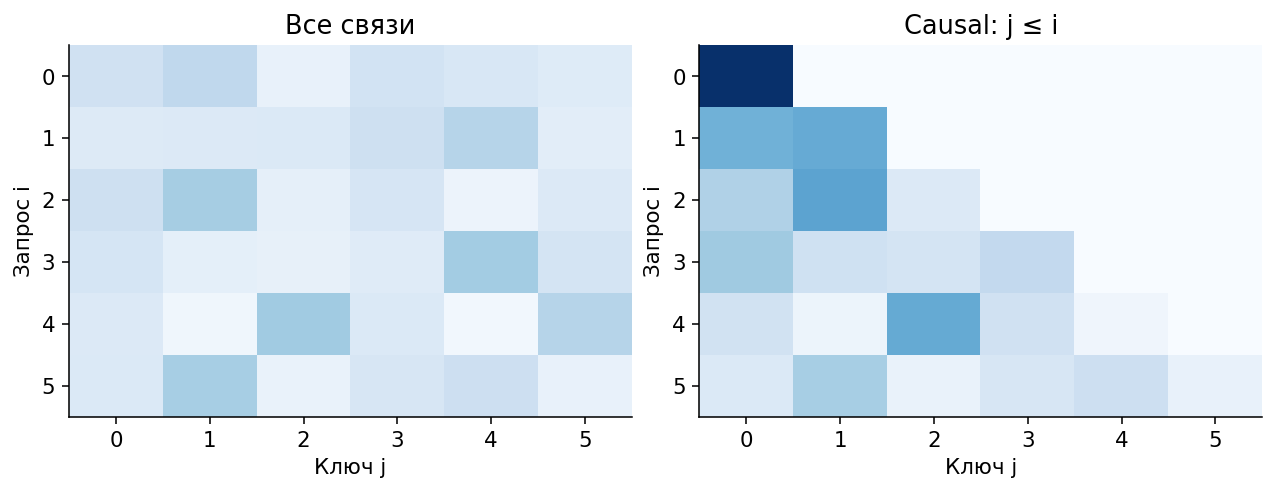

Суммы строк: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [4]:
def attention(q, k, v, causal=False):
    """Последние две оси: [T, d_h]; впереди могут быть batch и головы."""
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    if causal:
        length = q.shape[-2]
        allowed = torch.ones(length, length, dtype=torch.bool, device=q.device).tril()
        scores = scores.masked_fill(~allowed, float("-inf"))
    weights = scores.softmax(dim=-1)
    return weights @ v, weights


torch.manual_seed(7)
x = torch.randn(6, 8)
wq, wk, wv = [torch.randn(8, 4) / math.sqrt(8) for _ in range(3)]


def one_head(z, causal=False):
    return attention(z @ wq, z @ wk, z @ wv, causal=causal)


y, a = one_head(x)
yc, ac = one_head(x, causal=True)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
for ax, weights, title in zip(axes, [a, ac], ["Все связи", "Causal: j ≤ i"]):
    heatmap(ax, weights, title, vmin=0, vmax=1, cmap="Blues")
plt.show()
print("Суммы строк:", a.sum(-1).round(decimals=5).tolist())

**Вопрос 3.** Если поменять местами входные токены (без позиций и без маски), выход останется тем же или переставится? Ответьте до запуска следующей ячейки.

In [5]:
permutation = torch.tensor([2, 0, 5, 1, 4, 3])
y_permuted, _ = one_head(x[permutation])
yc_permuted, _ = one_head(x[permutation], causal=True)
error_free = (y_permuted - y[permutation]).abs().max().item()
error_causal = (yc_permuted - yc[permutation]).abs().max().item()
print(f"Без маски: max error = {error_free:.2e}")
print(f"С фиксированной causal mask: max error = {error_causal:.3f}")
torch.testing.assert_close(y_permuted, y[permutation], atol=1e-6, rtol=1e-5)
assert error_causal > 1e-3

Без маски: max error = 6.33e-08
С фиксированной causal mask: max error = 1.071


### Почему это работает
Пусть $P$ — матрица перестановки строк, $f$ — attention без маски и позиционной информации.
Тогда $Q'=PQ$, $K'=PK$, $V_a'=PV_a$:

$$S'=PSP^\top,\quad A'=PAP^\top,\quad
f(PX)=PAP^\top PV_a=Pf(X).$$

Использовали $P^\top P=I$, где $I$ — единичная матрица,
и то, что softmax по строкам согласован с перестановкой строк и столбцов.
С фиксированной треугольной маской произвольная перестановка меняет разрешённые связи.
Если одновременно переставить и маску как $PMP^\top$, эквивариантность сохраняется.

**Не путать:** causal mask ограничивает доступ; positional encoding сообщает о позиции.
Это разные механизмы. Наличие маски уже нарушает общую симметрию перестановок.

**Вопрос 4.** Если усреднить все выходные строки attention (без позиций и маски), что будет с результатом при перестановке входа? Как это связано с pooling в RAG?

## 3 · Позиционные представления
**Зачем:** «кот догнал пса» и «пёс догнал кота» — разные предложения, модель должна различать порядок.

| Вариант | Где применяется | Что обучается |
|---|---|---|
| Learned absolute | К $X_t$ добавляем строку позиционной таблицы $P_t$ | Сама таблица |
| Sinusoidal | К $X_t$ добавляем заданный вектор синусов и косинусов | Позиционная формула фиксирована |
| RoPE | В каждой голове вращаем $Q_t$ и $K_t$ | Здесь частоты фиксированы; проекции $W_Q,W_K$ обучаются |
| NoPE | Явного позиционного кодирования нет | Остальные веса; causal mask остаётся |

В этой таблице $P_t$ — вектор позиции, не матрица перестановки из предыдущего доказательства.
**NoPE не означает «никакого порядка»:** causal mask задаёт разные доступные префиксы.
Но это не гарантирует, что модель сама освоит нужную позиционную закономерность.

### Sinusoidal
Для чётного $d$, позиции $t$ и номера пары координат $j=0,\ldots,d/2-1$:

$$\omega_j=10000^{-2j/d},\quad
p_{t,2j}=\sin(t\omega_j),\quad p_{t,2j+1}=\cos(t\omega_j).$$

$p_t$ — позиционный вектор, $\omega_j$ — угловая частота. Разные пары отвечают за разные масштабы расстояний.
Перед первым блоком используем $X_t+p_t$.

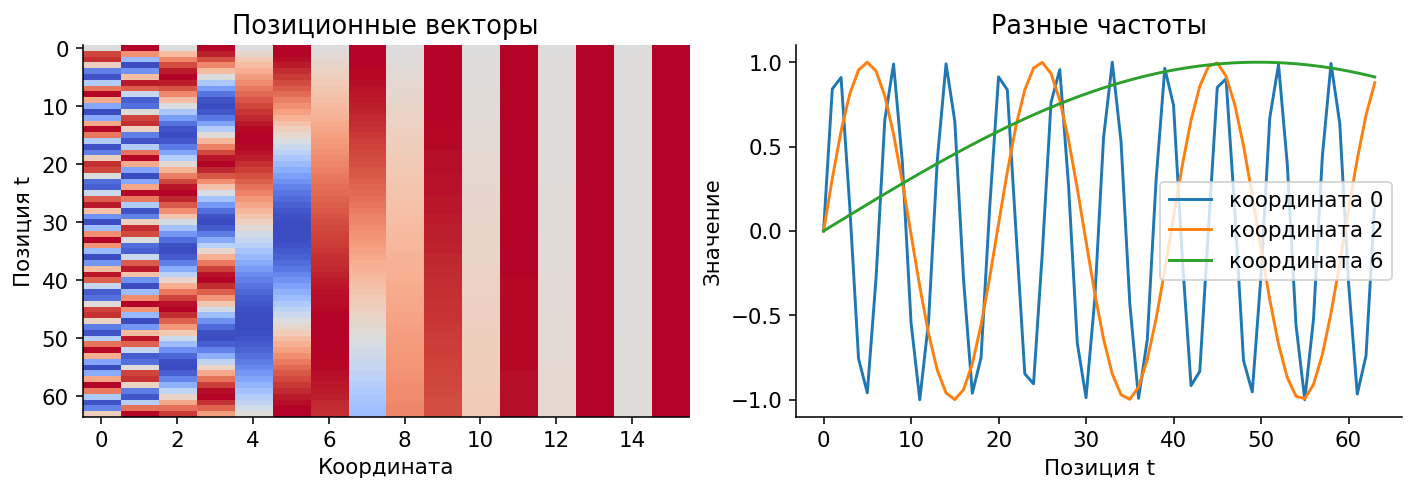

In [6]:
def sinusoidal_positions(length, width, device, offset=0):
    assert width % 2 == 0
    positions = torch.arange(offset, offset + length, device=device).float()
    frequencies = 10000.0 ** (-torch.arange(0, width, 2, device=device).float() / width)
    angles = positions[:, None] * frequencies[None, :]
    result = torch.empty(length, width, device=device)
    result[:, 0::2], result[:, 1::2] = angles.sin(), angles.cos()
    return result


pe = sinusoidal_positions(64, 16, DEVICE)
# emb = emb + pe
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
heatmap(axes[0], pe, "Позиционные векторы", "Координата", "Позиция t", cmap="coolwarm")
for coordinate in [0, 2, 6]:
    axes[1].plot(pe[:, coordinate], label=f"координата {coordinate}")
axes[1].set(title="Разные частоты", xlabel="Позиция t", ylabel="Значение")
axes[1].legend()
plt.show()

### RoPE: расстояние через вращение
**Rotary Position Embedding.** Разбиваем каждую голову на пары координат.
Пару из запроса в позиции $t$ вращаем на угол $t\omega_j$; ключ — аналогично.

$$R(\theta)=\begin{pmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{pmatrix},\qquad
\widetilde q_t=R(t\omega_j)q_t,\quad \widetilde k_s=R(s\omega_j)k_s.$$

Здесь $q_t,k_s\in\mathbb R^2$ — одна пара координат, $s,t$ — позиции,
$\theta$ — угол, $R$ — матрица вращения. Тогда

$$\widetilde q_t^\top\widetilde k_s
=q_t^\top R((s-t)\omega_j)k_s.$$

В **позиционной части** score появляется разность $s-t$.
Содержание $q_t,k_s$ тоже влияет: score не является функцией только расстояния.
Вращение сохраняет длину вектора; $V_a$ здесь не вращаем.
Для всей головы используем частоты $\omega_j=10000^{-2j/d_h}$.

Нормы сохранены; общий сдвиг позиций не меняет scores при фиксированных q, k.


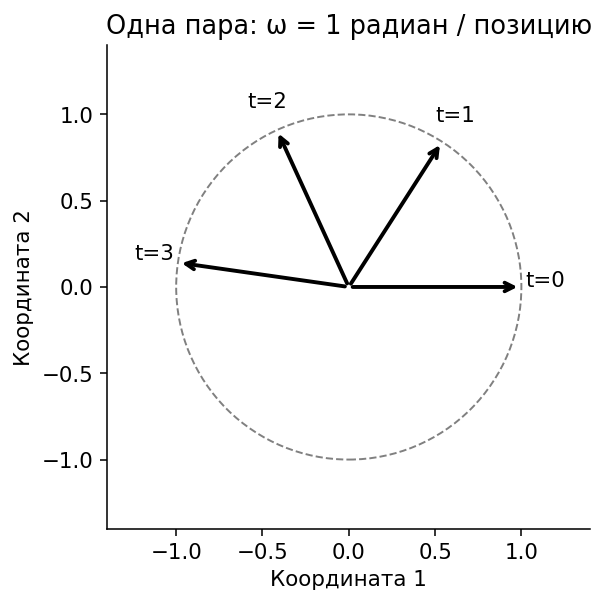

In [7]:
def apply_rope(z, positions):
    """z: [..., T, d_h]; positions: [T]. Вращаем соседние пары координат."""
    width = z.shape[-1]
    assert width % 2 == 0, "RoPE требует чётную ширину головы"
    frequencies = 10000.0 ** (-torch.arange(0, width, 2, device=z.device).float() / width)
    angles = positions.float()[:, None] * frequencies[None, :]
    cosine, sine = angles.cos().to(z.dtype), angles.sin().to(z.dtype)
    even, odd = z[..., 0::2], z[..., 1::2]
    rotated = torch.stack((even * cosine - odd * sine,
                           even * sine + odd * cosine), dim=-1)
    return rotated.flatten(-2)


q = torch.randn(1, 2, 6, 8)  # B=1, H=2, T=6, d_h=8
k = torch.randn_like(q)
positions = torch.arange(6)
qr, kr = apply_rope(q, positions), apply_rope(k, positions)
q_shift, k_shift = apply_rope(q, positions + 11), apply_rope(k, positions + 11)
torch.testing.assert_close(qr.norm(dim=-1), q.norm(dim=-1))
scores_rope = qr @ kr.transpose(-2, -1)
scores_shift = q_shift @ k_shift.transpose(-2, -1)
torch.testing.assert_close(scores_rope, scores_shift, atol=1e-5, rtol=1e-5)
print("Нормы сохранены; общий сдвиг позиций не меняет scores при фиксированных q, k.")

fig, ax = plt.subplots(figsize=(4.8, 4.2), constrained_layout=True)
for t in [0, 1, 2, 3]:
    point = apply_rope(torch.tensor([[1.0, 0.0]]), torch.tensor([t]))[0]
    ax.annotate("", xy=point.tolist(), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "lw": 2})
    ax.text(float(point[0]) * 1.14, float(point[1]) * 1.14, f"t={t}", ha="center")
ax.add_patch(plt.Circle((0, 0), 1, fill=False, linestyle="--", color="gray"))
ax.set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), xlabel="Координата 1",
       ylabel="Координата 2", title="Одна пара: ω = 1 радиан / позицию")
ax.set_aspect("equal")
plt.show()

**Вопрос 5.** Почему вращать $Q$ и $K$ на один и тот же угол для всех позиций бесполезно для кодирования расстояния?

### Длина контекста: вычислить формулу ≠ обобщить
- Learned-таблица ограничена выделенными строками; просто запросить несуществующую позицию нельзя.
- Sinusoidal и RoPE можно вычислить на новых позициях, но это **не гарантирует качество** на длинах вне обучения.
- NoPE не устраняет стоимость attention и не обещает перенос на произвольную длину.
- Сравнивать способы по качеству нужно после обучения с одинаковыми данными, бюджетом и отдельными тестами на длины.

Мы проверили алгебраическое свойство RoPE. Мы **не** доказали превосходство RoPE над sinusoidal.

**Вопрос 6.** Модель обучалась на $T=32$. Мы смогли вызвать RoPE на $T=128$. Какое утверждение пока НЕ проверено?

## 4 · Encoder и decoder: что доступно каждой позиции
**Зачем:** схема доступа к контексту должна соответствовать задаче обучения.

| Семейство | Доступ | Учебная задача |
|---|---|---|
| Encoder-only, BERT-подобное | Весь вход, кроме скрытого содержимого | Восстановить замаскированные токены |
| Decoder-only, GPT-подобное | Свой токен и предыдущие | Предсказать следующий токен |
| Encoder–decoder | Encoder видит вход; decoder — свой префикс и выходы encoder | Сгенерировать перевод |

**Self-attention:** $Q,K,V_a$ берём из одной последовательности.
**Cross-attention:** $Q$ — из decoder, $K,V_a$ — из выходов encoder.
Encoder и decoder — не последовательные стадии внутри BERT или GPT.

Здесь мы только сравниваем схемы доступа и собираем GPT-подобную модель. Если просто поменять маску,
BERT не получится: у него другие цель обучения, данные и детали архитектуры.

**Опыт:** изменим последние позиции. При causal attention выходы на предыдущих позициях
должны остаться прежними. Dropout (случайное зануление активаций при обучении) здесь не используется,
чтобы он не мешал сравнению.

In [8]:
x_changed = x.clone()
x_changed[4:] += 8.0  # меняем только будущее для позиций 0, 1, 2, 3
future_full, _ = one_head(x_changed)
future_causal, _ = one_head(x_changed, causal=True)
delta_full = (future_full[:4] - y[:4]).abs().max().item()
delta_causal = (future_causal[:4] - yc[:4]).abs().max().item()
print(f"Полный attention: изменение префикса = {delta_full:.4f}")
print(f"Causal attention: изменение префикса = {delta_causal:.4f}")
torch.testing.assert_close(future_causal[:4], yc[:4])
assert delta_full > 1e-3

# В обучении GPT вход и цель сдвинуты на один токен.
symbols = list("кот спит.")
print("Вход: ", symbols[:-1])
print("Цель: ", symbols[1:])
print("Предсказание в позиции t использует вход до t включительно, цель — токен t+1.")

Полный attention: изменение префикса = 8.3491
Causal attention: изменение префикса = 0.0000
Вход:  ['к', 'о', 'т', ' ', 'с', 'п', 'и', 'т']
Цель:  ['о', 'т', ' ', 'с', 'п', 'и', 'т', '.']
Предсказание в позиции t использует вход до t включительно, цель — токен t+1.


**Вопрос 7.** Зачем маска, если цель уже сдвинута на один токен? Почему при обучении все позиции считаются сразу, а при генерации — по одной?

> **Минутка юмора:** «Убрал causal mask — loss стал лучше. Кажется, изобрёл новую архитектуру».
> Модель: «Спасибо, ответы лежали в соседнем столбце».

Вывод: низкий loss ничего не значит, если модель видит информацию, недоступную ей при реальном применении.

## 5 · Собираем современный блок
**Зачем:** attention переносит информацию между токенами;
MLP (multilayer perceptron, многослойный перцептрон) преобразует признаки каждого токена;
остальные части помогают обучать глубокую модель.

### Residual connection — добавочное обновление
В pre-norm блоке нормализация стоит **перед** каждой ветвью:

$$U=X+\operatorname{Attention}(\operatorname{Norm}(X)),$$
$$Z=U+\operatorname{MLP}(\operatorname{Norm}(U)).$$

$U$ — промежуточное состояние, $Z$ — выход блока. Все слагаемые имеют размер $B\times T\times d$.
Слой учится добавлять поправку к текущему представлению.
Для ветви $f$ производная $x+f(x)$ равна $I+J_f$, где $J_f$ — матрица производных $f$ по $x$.
Есть прямой путь градиента; это помогает оптимизации, но не гарантирует её устойчивость.

### RMSNorm — контроль масштаба вектора
Для одного токена $x\in\mathbb R^d$:

$$\operatorname{RMSNorm}(x)_i=
\gamma_i\frac{x_i}{\sqrt{\frac1d\sum_{j=1}^d x_j^2+\varepsilon}}.$$

$\gamma\in\mathbb R^d$ — обучаемый масштаб по координатам; $\varepsilon>0$ — численная защита.
RMS означает root mean square, среднеквадратическую величину.
**LayerNorm** дополнительно вычитает среднее $\mu=\frac1d\sum_j x_j$ и нормирует по дисперсии.
Обе операции работают по признакам **каждого токена отдельно**, не по batch и не по времени.

In [9]:
class RMSNorm(nn.Module):
    def __init__(self, width, eps=1e-6):
        super().__init__()
        self.scale = nn.Parameter(torch.ones(width))
        self.eps = eps

    def forward(self, x):
        inverse_rms = torch.rsqrt(x.float().square().mean(dim=-1, keepdim=True) + self.eps)
        return (x.float() * inverse_rms).to(x.dtype) * self.scale


norm_input = torch.tensor([[1.0, 2.0, 3.0, 4.0], [11.0, 12.0, 13.0, 14.0]])
layer_norm = nn.LayerNorm(4, elementwise_affine=False, eps=1e-6)
rms_norm = RMSNorm(4)
print("LayerNorm:", layer_norm(norm_input))
print("RMSNorm:", rms_norm(norm_input).detach())
torch.testing.assert_close(layer_norm(norm_input)[0], layer_norm(norm_input)[1])

LayerNorm: tensor([[-1.3416, -0.4472,  0.4472,  1.3416],
        [-1.3416, -0.4472,  0.4472,  1.3416]])
RMSNorm: tensor([[0.3651, 0.7303, 1.0954, 1.4606],
        [0.8765, 0.9562, 1.0359, 1.1155]])


**Вопрос 8.** Во второй строке ко всем координатам добавлено 10. Почему LayerNorm дал одинаковые строки, а RMSNorm — разные?

### SwiGLU — управляемое преобразование признаков
Обычный MLP: $\operatorname{ReLU}(XW_1)W_2$,
где $\operatorname{ReLU}(z)=\max(0,z)$.

$$\operatorname{SwiGLU}(X)=
\big[\operatorname{SiLU}(XW_g)\odot (XW_u)\big]W_d,$$
$$\operatorname{SiLU}(z)=z\sigma(z),\quad \sigma(z)=1/(1+e^{-z}).$$

$W_g,W_u\in\mathbb R^{d\times d_{ff}}$ — gate и up проекции,
$W_d\in\mathbb R^{d_{ff}\times d}$ — down проекция; $\odot$ — поэлементное умножение.
Одна ветвь модулирует другую. Значения SiLU **не ограничены интервалом [0,1]**:
gate здесь не вероятность и не бинарный выбор эксперта.

Без bias обычный MLP с $d_{ff}=4d$ содержит $8d^2$ весов;
SwiGLU — $3dd_{ff}$. Для примерно равного бюджета выбирают $d_{ff}\approx8d/3$.
**Bias** — добавляемый обучаемый вектор смещения; ниже проекции без bias.

В формулах векторы записаны строками; `nn.Linear(a, b)` хранит веса как `[b, a]`
и вычисляет `x @ weight.T`. Это та же операция с другой конвенцией хранения.

In [10]:
class FeedForward(nn.Module):
    def __init__(self, width, hidden, kind="swiglu"):
        super().__init__()
        if kind not in {"relu", "swiglu"}:
            raise ValueError(kind)
        self.kind = kind
        self.up = nn.Linear(width, hidden, bias=False)
        self.down = nn.Linear(hidden, width, bias=False)
        if kind == "swiglu":
            self.gate = nn.Linear(width, hidden, bias=False)

    def forward(self, x):
        if self.kind == "swiglu":
            hidden = F.silu(self.gate(x)) * self.up(x)
        else:
            hidden = F.relu(self.up(x))
        return self.down(hidden)


width_demo = 48
mlp_relu = FeedForward(width_demo, 4 * width_demo, "relu")
mlp_swiglu = FeedForward(width_demo, 8 * width_demo // 3, "swiglu")
for name, module in [("ReLU", mlp_relu), ("SwiGLU", mlp_swiglu)]:
    print(name, "число весов:", sum(p.numel() for p in module.parameters()))

ReLU число весов: 18432
SwiGLU число весов: 18432


### Multi-head attention: несколько способов прочитать контекст
В каждой голове — собственные проекции $Q,K,V_a$. Выходы голов конкатенируем
(соединяем по признакам), затем применяем обучаемую выходную проекцию $W_O\in\mathbb R^{d\times d}$.

Размеры: `[B,T,d] → [B,H,T,d_h] → scores [B,H,T,T] → [B,T,d]`.
`reshape` меняет разбиение осей, `transpose` меняет порядок осей.
Мы сохраняем все $d$ признаков, а не усредняем головы.

Далее одна реализация поддерживает полный/causal attention и RoPE.
GQA, sparse attention и KV-cache — на следующем занятии.

In [11]:
class MultiHeadAttention(nn.Module):
    def __init__(self, width, heads, rope=False):
        super().__init__()
        assert width % heads == 0
        self.heads, self.head_dim = heads, width // heads
        assert not rope or self.head_dim % 2 == 0
        self.rope = rope
        self.query = nn.Linear(width, width, bias=False)
        self.key = nn.Linear(width, width, bias=False)
        self.value = nn.Linear(width, width, bias=False)
        self.out = nn.Linear(width, width, bias=False)

    def forward(self, x, causal=True, offset=0):
        batch, length, width = x.shape

        def split_heads(projection):
            return projection(x).reshape(batch, length, self.heads, self.head_dim).transpose(1, 2)

        q, k, v = [split_heads(proj) for proj in (self.query, self.key, self.value)]
        if self.rope:
            positions = torch.arange(offset, offset + length, device=x.device)
            q, k = apply_rope(q, positions), apply_rope(k, positions)
        result, _ = attention(q, k, v, causal=causal)
        result = result.transpose(1, 2).contiguous().reshape(batch, length, width)
        return self.out(result)


class TransformerBlock(nn.Module):
    def __init__(self, width, heads, hidden, rope, norm="rms", mlp="swiglu"):
        super().__init__()
        if norm not in {"rms", "layer"}:
            raise ValueError(norm)
        norm_class = RMSNorm if norm == "rms" else nn.LayerNorm
        self.norm1, self.norm2 = norm_class(width), norm_class(width)
        self.attn = MultiHeadAttention(width, heads, rope=rope)
        self.mlp = FeedForward(width, hidden, kind=mlp)

    def forward(self, x, causal=True, offset=0):
        x = x + self.attn(self.norm1(x), causal=causal, offset=offset)
        return x + self.mlp(self.norm2(x))


block = TransformerBlock(width=48, heads=3, hidden=128, rope=True)
block_input = torch.randn(2, 10, 48, requires_grad=True)
block_output = block(block_input)
block_output.square().mean().backward()
print("Вход / выход:", tuple(block_input.shape), tuple(block_output.shape))
print("Норма градиента по входу:", round(block_input.grad.norm().item(), 4))
assert torch.isfinite(block_input.grad).all()

Вход / выход: (2, 10, 48) (2, 10, 48)
Норма градиента по входу: 0.0658


**Вопрос 9.** Какие части блока смешивают разные позиции, а какие обрабатывают каждый токен отдельно? Почему residual требует одинаковой ширины?

## 6 · От блока к языковой модели

После $N$ блоков: финальная нормализация и линейная проекция $d\to V$.
**Logits** $\ell_{b,t,v}$ — ненормированные оценки токенов словаря.
Индекс $b$ — последовательность в batch, $t$ — позиция, $v$ — токен словаря.

$$p(v\mid s_{\le t})=\operatorname{softmax}(\ell_{b,t,:})_v,$$
$$\mathcal L=-\frac1{BT}\sum_{b=1}^{B}\sum_{t=1}^{T}
\log p(y_{b,t}\mid s_{b,\le t}),\qquad y_{b,t}=s_{b,t+1}.$$

$\mathcal L$ — средняя cross-entropy (отрицательный log-likelihood);
$y$ — правильный следующий токен, $s_{\le t}$ — видимый префикс.
В `F.cross_entropy` передаём **logits**, не вероятности: log-softmax уже внутри.

Позиции `learned` / `sinusoidal` добавляются перед блоками;
`rope` применяется к $Q,K$ внутри каждой головы; `none` — NoPE.
Это удобный переключатель для опытов, а не готовый честный benchmark способов.

In [12]:
@dataclass
class ModelConfig:
    vocab_size: int
    width: int = 48
    heads: int = 3
    hidden: int = 128
    layers: int = 2
    max_len: int = 48
    position: str = "rope"
    norm: str = "rms"
    mlp: str = "swiglu"


class TinyLM(nn.Module):
    def __init__(self, config):
        super().__init__()
        if config.position not in {"learned", "sinusoidal", "rope", "none"}:
            raise ValueError(config.position)
        self.config = config
        self.tokens = nn.Embedding(config.vocab_size, config.width)
        if config.position == "learned":
            self.positions = nn.Embedding(config.max_len, config.width)
        self.blocks = nn.ModuleList([
            TransformerBlock(config.width, config.heads, config.hidden,
                             rope=config.position == "rope", norm=config.norm, mlp=config.mlp)
            for _ in range(config.layers)
        ])
        norm_class = RMSNorm if config.norm == "rms" else nn.LayerNorm
        self.final_norm = norm_class(config.width)
        self.lm_head = nn.Linear(config.width, config.vocab_size, bias=False)

    def forward(self, ids, causal=True):
        _, length = ids.shape
        x = self.tokens(ids)
        if self.config.position == "learned":
            if length > self.config.max_len:
                raise ValueError("Позиция вне обучаемой таблицы")
            x = x + self.positions(torch.arange(length, device=ids.device))
        elif self.config.position == "sinusoidal":
            x = x + sinusoidal_positions(length, self.config.width, ids.device).to(x.dtype)
        for block in self.blocks:
            x = block(x, causal=causal)
        return self.lm_head(self.final_norm(x))

### Данные: маленький язык с проверяемыми правилами
Корпус создаётся локально: «кот спит.», «пёс бежит.» и другие короткие предложения.
Для каждого существительного есть свой набор глаголов.
Train и validation — независимые выборки из одной игрушечной грамматики;
предложения могут совпадать. Это проверка усвоения распределения, **не тест новых знаний**.
Словарь заранее задан всей грамматикой. Все окна в batch одинаковой длины,
padding (дополнение коротких последовательностей служебными токенами) не нужен.

**Baseline** — простое решение для сравнения. Возьмём равномерный прогноз и биграммную модель:
биграмма оценивает следующий символ только по текущему.

In [13]:
GRAMMAR = {
    "кот": ["спит", "ест", "мурчит"],
    "пёс": ["спит", "ест", "лает"],
    "ёж": ["спит", "ест", "бежит"],
}


def make_corpus(count, seed):
    rng = random.Random(seed)
    sentences = []
    for _ in range(count):
        noun = rng.choice(list(GRAMMAR))
        verb = rng.choice(GRAMMAR[noun])
        sentences.append(f"{noun} {verb}.\n")
    return "".join(sentences)


alphabet = "".join(f"{noun} {verb}.\n" for noun, verbs in GRAMMAR.items() for verb in verbs)
tokenizer = CharTokenizer(alphabet)
train_text, val_text = make_corpus(2000, 1), make_corpus(400, 2)
train_ids = torch.tensor(tokenizer.encode(train_text), dtype=torch.long, device=DEVICE)
val_ids = torch.tensor(tokenizer.encode(val_text), dtype=torch.long, device=DEVICE)
config = ModelConfig(vocab_size=len(tokenizer))


def get_batch(data, batch_size, length, generator):
    starts = torch.randint(len(data) - length, (batch_size,), generator=generator)
    inputs = torch.stack([data[int(i):int(i) + length] for i in starts])
    targets = torch.stack([data[int(i) + 1:int(i) + length + 1] for i in starts])
    return inputs, targets


train_rng = torch.Generator().manual_seed(10)
val_rng = torch.Generator().manual_seed(20)
eval_x, eval_y = get_batch(val_ids, 64, config.max_len, val_rng)
print("Словарь:", tokenizer.tokens, "| V =", len(tokenizer))
print("Пример train:\n" + train_text[:90])
print("Формы eval:", tuple(eval_x.shape), tuple(eval_y.shape))

# Аддитивное сглаживание +1: ни один переход не имеет нулевой вероятности.
transition_counts = torch.ones(len(tokenizer), len(tokenizer), device=DEVICE)
for previous, following in zip(train_ids[:-1], train_ids[1:]):
    transition_counts[previous, following] += 1
bigram_prob = transition_counts / transition_counts.sum(dim=1, keepdim=True)
bigram_loss = -bigram_prob[eval_x, eval_y].log().mean().item()
uniform_loss = math.log(len(tokenizer))
print(f"Validation CE: uniform={uniform_loss:.3f}; bigram={bigram_loss:.3f}")

Словарь: ['\n', ' ', '.', 'а', 'б', 'е', 'ж', 'и', 'к', 'л', 'м', 'о', 'п', 'р', 'с', 'т', 'у', 'ч', 'ё'] | V = 19
Пример train:
кот мурчит.
кот ест.
кот ест.
пёс ест.
ёж ест.
кот спит.
пёс спит.
пёс ест.
ёж спит.
ёж ес
Формы eval: (64, 48) (64, 48)
Validation CE: uniform=2.944; bigram=0.658


### Обучение: тот же цикл, новая функция модели
`AdamW` — оптимизатор, использующий накопленные оценки градиентов и их квадратов;
`lr` — learning rate, размер шага; `weight_decay` — сила отдельного уменьшения весов.
Настройки здесь фиксированные, вывод AdamW выходит за рамки этого ноутбука.

`zero_grad` очищает накопленные градиенты → `backward` вычисляет новые → `step` меняет веса.
Gradient clipping ограничивает общую норму градиентов; это защита от слишком больших шагов.
Validation считаем без изменения весов и без построения графа производных.

Обучение занимает несколько секунд на CPU. Обратите внимание: снижение loss показывает, что модель учится на игрушечных данных,
но ничего не говорит о преимуществе выбранных архитектурных модификаций.

step= 30 | train CE=0.430 | val CE=0.429
step= 60 | train CE=0.277 | val CE=0.270
step= 90 | train CE=0.262 | val CE=0.255
step=120 | train CE=0.242 | val CE=0.254
step=150 | train CE=0.257 | val CE=0.254
step=180 | train CE=0.242 | val CE=0.251
Обучение заняло 2.2 с на этом компьютере.
Параметров: 57360
Validation CE: до=3.127, после=0.251


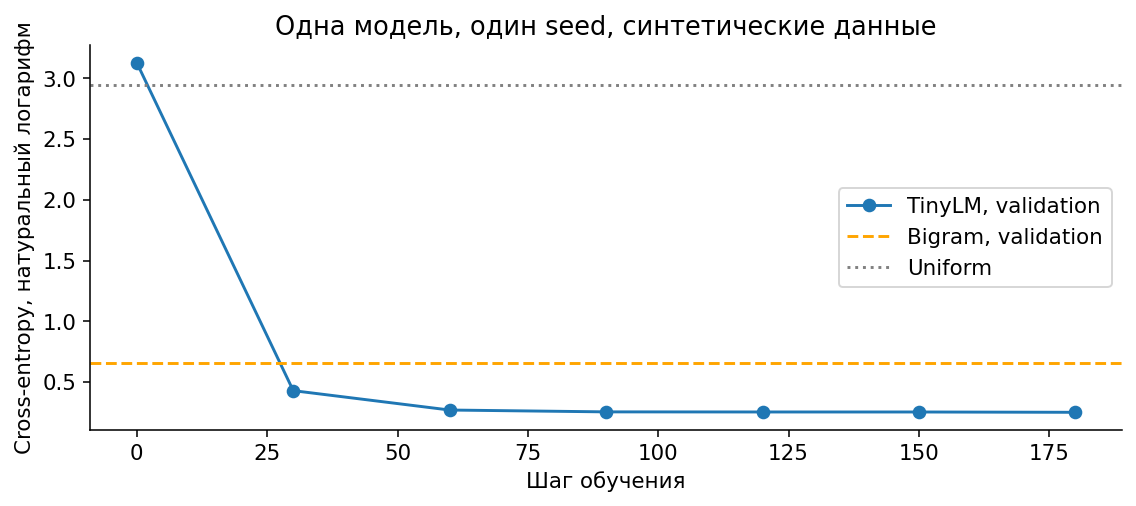

In [14]:
@torch.no_grad()
def evaluate(model, inputs, targets):
    was_training = model.training
    model.eval()
    logits = model(inputs)
    loss = F.cross_entropy(logits.flatten(0, 1), targets.flatten()).item()
    model.train(was_training)
    return loss


torch.manual_seed(SEED)
model = TinyLM(config).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01)
initial_loss = evaluate(model, eval_x, eval_y)
history = [(0, initial_loss)]
start_time = time.perf_counter()
if RUN_TRAINING:
    model.train()
    for step in range(1, TRAIN_STEPS + 1):
        inputs, targets = get_batch(train_ids, 16, config.max_len, train_rng)
        logits = model(inputs)
        loss = F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        if step % 30 == 0 or step == TRAIN_STEPS:
            val_loss = evaluate(model, eval_x, eval_y)
            history.append((step, val_loss))
            print(f"step={step:3d} | train CE={loss.item():.3f} | val CE={val_loss:.3f}")
    print(f"Обучение заняло {time.perf_counter() - start_time:.1f} с на этом компьютере.")
else:
    print("Обучение пропущено: далее случайная, необученная модель.")

print("Параметров:", sum(p.numel() for p in model.parameters()))
print(f"Validation CE: до={initial_loss:.3f}, после={history[-1][1]:.3f}")
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(*zip(*history), marker="o", label="TinyLM, validation")
ax.axhline(bigram_loss, color="orange", linestyle="--", label="Bigram, validation")
ax.axhline(uniform_loss, color="gray", linestyle=":", label="Uniform")
ax.set(xlabel="Шаг обучения", ylabel="Cross-entropy, натуральный логарифм",
       title="Одна модель, один seed, синтетические данные")
ax.legend()
plt.show()

**Вопрос 10.** Почему биграммной модели трудно выбрать между «лает» и «мурчит» после пробела, а Transformer потенциально может? Как это проверить на обученной модели?

### Генерация: выбираем токен и возвращаем его на вход
Берём logits последней позиции; сэмплируем (случайно выбираем) следующий токен.
**Температура** $\tau>0$ меняет распределение:
$p=\operatorname{softmax}(\ell/\tau)$. Маленькая $\tau$ делает выбор более концентрированным.
При $\tau=0$ в коде отдельно выбираем argmax, то есть максимальный logit.
Это не повышает достоверность модели автоматически.

Если префикс длиннее `max_len`, берём последние `max_len` токенов.
Это простое ограничение контекста, не KV-cache; каждый шаг пересчитывает весь видимый контекст.

In [15]:
@torch.no_grad()
def generate(model, tokenizer, prompt, new_tokens=120, temperature=0.8):
    if not prompt or temperature < 0:
        raise ValueError("Нужен непустой prompt и temperature >= 0")
    was_training = model.training
    model.eval()
    ids = torch.tensor([tokenizer.encode(prompt)], device=next(model.parameters()).device)
    for _ in range(new_tokens):
        context = ids[:, -model.config.max_len:]
        logits = model(context)[:, -1, :]
        if temperature == 0:
            next_id = logits.argmax(dim=-1, keepdim=True)
        else:
            probabilities = (logits / temperature).softmax(dim=-1)
            next_id = torch.multinomial(probabilities, num_samples=1)
        ids = torch.cat((ids, next_id), dim=1)
    model.train(was_training)
    return tokenizer.decode(ids[0].tolist())


torch.manual_seed(123)
print("ОБУЧЕННАЯ МОДЕЛЬ" if RUN_TRAINING else "СЛУЧАЙНАЯ МОДЕЛЬ")
print(generate(model, tokenizer, "кот "))

ОБУЧЕННАЯ МОДЕЛЬ
кот спит.
кот ест.
кот мурчит.
ёж спит.
пёс спит.
ёж ест.
ёж ест.
ёж ест.
ёж ест.
пёс ест.
кот мурчит.
ёж ест.
кот мурчит.
к


### Проверка всей модели: не подсматривает ли она будущее?
Одноголовый attention уже проверили. Теперь проверяем композицию двух блоков,
нормализаций и MLP. При causal mask выходы префикса должны совпасть.
Это содержательный тест архитектуры: случайное смешивание времени в нормализации или ошибка маски его нарушит.

In [16]:
model.eval()
check_ids = eval_x[:1, :12].clone()
changed_ids = check_ids.clone()
cut = 7
changed_ids[:, cut:] = (changed_ids[:, cut:] + 1) % len(tokenizer)
with torch.no_grad():
    original_logits = model(check_ids)
    changed_logits = model(changed_ids)
torch.testing.assert_close(original_logits[:, :cut], changed_logits[:, :cut], atol=1e-6, rtol=1e-5)
print("Вся TinyLM: logits до изменённого будущего совпадают.")

# Варианты выполняют forward; это проверка реализации, не сравнение качества.
variants = [(position, ModelConfig(vocab_size=len(tokenizer), position=position))
            for position in ["learned", "sinusoidal", "rope", "none"]]
variants.append(("learned + LayerNorm + ReLU", ModelConfig(
    vocab_size=len(tokenizer), position="learned", norm="layer", mlp="relu", hidden=192)))
for name, variant_config in variants:
    candidate = TinyLM(variant_config)
    with torch.no_grad():
        result = candidate(eval_x[:2, :8])
    assert result.shape == (2, 8, len(tokenizer)) and torch.isfinite(result).all()
    print(name, "→", tuple(result.shape))

Вся TinyLM: logits до изменённого будущего совпадают.
learned → (2, 8, 19)
sinusoidal → (2, 8, 19)
rope → (2, 8, 19)
none → (2, 8, 19)
learned + LayerNorm + ReLU → (2, 8, 19)


**Вопрос 11.** Что изменить в этом коде, чтобы честно исследовать влияние позиционного представления на качество? Почему нельзя просто сравнить четыре случайных forward?

### Итоги
1. **Токены и embeddings:** дискретный адрес → обучаемый вектор.
2. **Attention и порядок:** обмен информацией между позициями; без позиций и маски — эквивариантность.
3. **Позиции:** добавление вектора или вращение Q/K; работа на новой длине не гарантирует качество.
4. **Encoder и decoder:** доступ к контексту должен соответствовать цели обучения.
5. **Блок:** residual + нормализация + attention + MLP.
6. **LM:** logits → cross-entropy при обучении; последовательный выбор токенов при генерации.

**Что теперь можно прочитать в конфиге реальной модели:** embeddings, число голов, ширину,
позиционный механизм, MLP и residual. Следующий вопрос: почему длинный контекст такой дорогой?

Ниже — дополнительные задачи для самостоятельной работы.

## ★ Дополнительно · задачи для самостоятельной работы
Сначала сформулируйте ответ, потом откройте решение.

**A. Доказать эквивариантность.** Заполните пропущенный шаг:
почему $\operatorname{softmax}(PSP^\top)=P\operatorname{softmax}(S)P^\top$?

<details><summary>Решение</summary>

Перестановка строк переставляет независимые операции softmax.
Перестановка столбцов переставляет слагаемые в знаменателе, не меняя их сумму,
и переставляет числители тем же образом. Для каждой строки результат переставляется согласованно.

</details>

**B. Посчитать параметры.** При $d=48$, $H=3$, $d_{ff}=128$ сколько весов
в одном нашем блоке? Учитывайте две RMSNorm. Что изменится при $H=6$ и фиксированном $d$?

<details><summary>Решение</summary>

Attention: четыре проекции, $4d^2=9216$.
SwiGLU: $3dd_{ff}=18432$.
Две RMSNorm: $2d=96$. Итого **27744**.
При другой допустимой величине H число весов тех же полных проекций не меняется;
меняется разбиение признаков на головы. Для RoPE ширина головы должна быть чётной.

</details>

**C. Сравнить градиенты.** Какие производные появятся в SwiGLU из-за поэлементного произведения?

<details><summary>Решение</summary>

Пусть $a=XW_g$, $b=XW_u$, $h=\operatorname{SiLU}(a)\odot b$,
а $g_h$ — градиент loss по $h$.
Тогда $g_a=g_h\odot b\odot\operatorname{SiLU}'(a)$,
$g_b=g_h\odot\operatorname{SiLU}(a)$.
Производная SiLU: $\sigma(a)+a\sigma(a)(1-\sigma(a))$ поэлементно.
Градиент по X складывается от двух ветвей. Gate не означает выключение backward.

</details>

**D. Спроектировать тест на длину.** Почему наша грамматика имён животных плохо подходит
для доказательства переноса на длинный контекст?

<details><summary>Решение</summary>

Полезные зависимости короткие. Можно увеличить T и получить низкий средний loss,
не используя далёкие токены. Нужна задача с контролируемым расстоянием между условием и ответом:
например, сохранить заданный в начале символ и вернуть его после случайного заполнителя.
Оценивать точность именно ответа отдельно по длинам; не усреднять её с простыми токенами заполнителя.

</details>

In [17]:
expected_block_parameters = 4 * 48**2 + 3 * 48 * 128 + 2 * 48
assert sum(p.numel() for p in block.parameters()) == expected_block_parameters
print("Число параметров блока:", expected_block_parameters)

# Явный attention и библиотечная реализация той же математической операции.
torch.manual_seed(50)
q_test, k_test, v_test = [torch.randn(2, 3, 7, 8) for _ in range(3)]
manual, _ = attention(q_test, k_test, v_test, causal=True)
reference = F.scaled_dot_product_attention(q_test, k_test, v_test,
                                         dropout_p=0.0, is_causal=True)
torch.testing.assert_close(manual, reference, atol=1e-6, rtol=1e-5)
print("Явный attention совпал с PyTorch SDPA при dropout=0.")

Число параметров блока: 27744
Явный attention совпал с PyTorch SDPA при dropout=0.


**Обсуждение:** библиотечная функция может выбирать разные вычислительные реализации.
Совпадение формулы и выходов не означает одинаковую скорость и расход памяти.
Замену реализации attention и изменение самой архитектуры разберём в следующей теме.

**★ Ещё один опыт: NoPE и одинаковые токены.** Causal mask нарушает произвольную
перестановочную симметрию, но обязана ли она различать все позиции одинакового входа?
Предскажите результат следующей ячейки.

In [18]:
nope_block = TransformerBlock(width=48, heads=3, hidden=128, rope=False).eval()
identical_input = torch.ones(1, 6, 48)
with torch.no_grad():
    identical_output = nope_block(identical_input, causal=True)
torch.testing.assert_close(identical_output, identical_output[:, :1].expand_as(identical_output))
print("У одинаковых токенов без позиций выходы совпадают даже с causal mask.")

У одинаковых токенов без позиций выходы совпадают даже с causal mask.


<details><summary>Почему? И почему это не противоречит разговору о NoPE?</summary>

Все ключи и значения одинаковы. Усреднение одного, двух или шести одинаковых значений
даёт тот же вектор. Поэлементные по токенам MLP и нормализации сохраняют равенство.
Маска создаёт возможность использовать структуру префикса, но не кодирует номер позиции
явно и не гарантирует различимость на любом входе. Специальный стартовый токен уже изменил бы условие опыта.

</details>

## Источники и границы реализации
- [Andrej Karpathy — Let's build GPT / код](https://github.com/karpathy/ng-video-lecture):
  источник подхода «маленькая LM с нуля». Этот ноутбук — самостоятельная адаптация,
  не дословная копия: добавлены BPE-демо, проверки симметрии,
  sinusoidal/RoPE/NoPE, RMSNorm, SwiGLU, синтетический корпус, baseline и вопросы.
- [Attention Is All You Need](https://arxiv.org/abs/1706.03762): attention, многоголовость, sinusoidal.
- [BERT](https://arxiv.org/abs/1810.04805): двунаправленный encoder и masked language modeling.
- [RoFormer / RoPE](https://arxiv.org/abs/2104.09864): позиционные вращения.
- [The Impact of Positional Encoding on Length Generalization](https://arxiv.org/abs/2305.19466): NoPE и перенос по длине.
- [RMSNorm](https://arxiv.org/abs/1910.07467).
- [GLU Variants Improve Transformer](https://arxiv.org/abs/2002.05202): SwiGLU.
- [BPE для подслов](https://arxiv.org/abs/1508.07909).
- [PyTorch SDPA](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html).

**Упрощения:** символьная LM; никаких pretrained-весов; полный явный attention;
нет padding, dropout, KV-cache, weight tying (общих весов входной и выходной таблиц),
смешанной точности и распределённого обучения. Учебный BPE не заменяет production-токенизатор.
Реализованные варианты не воспроизводят целиком BERT, GPT-2 или Mistral.
По небольшому корпусу нельзя делать выводы о качестве больших моделей.